# Question 2: Transactions as matrices and vectors

This notebook draws the sample of up to 2,000 transactions, builds the matrix
X, computes the mean vector, standardises the sample and measures the geometry
of two standardised transaction vectors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import csc1105 as cs

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.4


In [2]:
analysis_df = cs.load_clean(verbose=False)
sample, X = cs.sample_matrix(analysis_df)     # random_state=1105
n = X.shape[0]
print("sample rows n =", n)
print("X shape       =", X.shape)

sample rows n = 2000
X shape       = (2000, 5)


## 2(a) Three actual rows, with the coordinates named

Coordinate order is fixed by the assignment and must not be changed: the matrix
`B` in Question 3 is written for this order.

In [3]:
print("coordinates:", cs.COLS)
print()
for i in range(3):
    print(f"x_{i+1} =", np.array2string(X[i], formatter={"float_kind": lambda v: f"{v:,.2f}"}))

coordinates: ['amount', 'oldBalInitiator', 'newBalInitiator', 'oldBalRecipient', 'newBalRecipient']

x_1 = [89,326.69 4,146,868.50 4,057,541.81 158,658.84 158,658.84]
x_2 = [16,857.65 3,322,689.44 3,305,831.79 64,479.96 81,337.61]
x_3 = [17,133.51 3,313,699.33 3,296,565.82 74,506.55 91,640.05]


### Dimensions and meanings

| matrix | shape | one entry means |
|---|---|---|
| `X` | n x 5 | quantity *j* of transaction *i* |
| `X.T` | 5 x n | column *i* is the transaction vector x_i |
| `X.T @ X` | 5 x 5 | a sum over all transactions relating two *quantities* |
| `X @ X.T` | n x n | the dot product of two *transactions* |

Both products are symmetric. `X.T @ X` does not grow with the number of
transactions, which is why it is the one used in practice; `X @ X.T` would have
n squared entries.

In [4]:
print("X      ", X.shape)
print("X.T    ", X.T.shape)
print("X.T @ X", (X.T @ X).shape)
print("X @ X.T", (X @ X.T).shape, f"  ({n*n:,} entries)")
print()
print("symmetric?", np.allclose(X.T @ X, (X.T @ X).T))

X       (2000, 5)
X.T     (5, 2000)
X.T @ X (5, 5)
X @ X.T (2000, 2000)   (4,000,000 entries)

symmetric? True


**Why identifiers and transaction types are excluded.** The five chosen columns
are measured quantities on a common scale of money, so sums, averages and
distances mean something. Account identifiers are *names*: account 2000 is not
twice account 1000, and the gap between two identifiers measures nothing.
Transaction types are unordered categories. Including either would not raise an
error, it would produce numbers that look valid and mean nothing.

## 2(b) The mean vector

In [5]:
ones = np.ones(n)
col_sums = X.T @ ones
mu = col_sums / n

for name, s, m in zip(cs.COLS, col_sums, mu):
    print(f"  {name:18s} sum={s:18,.2f}   mean={m:14,.4f}")

print()
print("matches pandas column means:",
      np.allclose(mu, sample[cs.COLS].mean().to_numpy()))

  amount             sum=    113,112,898.32   mean=   56,556.4492
  oldBalInitiator    sum=  4,814,195,411.33   mean=2,407,097.7057
  newBalInitiator    sum=  4,835,797,794.23   mean=2,417,898.8971
  oldBalRecipient    sum=    232,860,409.47   mean=  116,430.2047
  newBalRecipient    sum=    265,993,129.89   mean=  132,996.5649

matches pandas column means: True


In [6]:
# the total amount is a dot product with the vector of ones
a = X[:, 0]
total = a @ ones
print(f"total amount = a . 1 = {total:,.2f}")
print(f"n * mu_1             = {n * mu[0]:,.2f}")
print("equal:", np.isclose(total, n * mu[0]))

total amount = a . 1 = 113,112,898.32
n * mu_1             = 113,112,898.32
equal: True


**A column of X lies in R^n, a row lies in R^5.** They are indexed by different
things. A column records one quantity across every transaction, so it has one
entry per transaction. A row records all five quantities for one transaction.
With n = 2000 the first column lies in R^2000 while x_1 still lies in R^5, so a
dot product between a column and a row is not even defined.

## 2(c) Standardise, then measure

Standardising uses the n - 1 divisor, matching the starter code given in the
assignment. The question asks for two **nonzero** vectors, so the first two rows
with nonzero norm are selected rather than assuming rows 0 and 1 qualify.

In [7]:
Z, mu, s = cs.standardise(X)
print("s (ddof=1):")
for name, v in zip(cs.COLS, s):
    print(f"  {name:18s} {v:16,.4f}")

u, v, idx = cs.two_nonzero_rows(Z)
print()
print("rows used for u and v:", idx)

s (ddof=1):
  amount                  95,961.5971
  oldBalInitiator      1,327,881.3988
  newBalInitiator      1,319,784.1435
  oldBalRecipient        327,073.2783
  newBalRecipient        369,815.9742

rows used for u and v: [0 1]


In [8]:
nu, nv, dist, dot, cos, angle = cs.angle_between(u, v)
print(f"||u||        = {nu:.6f}")
print(f"||v||        = {nv:.6f}")
print(f"||u - v||    = {dist:.6f}")
print(f"u . v        = {dot:.6f}")
print(f"cos(theta)   = {cos:.6f}")
print(f"angle        = {angle:.4f} degrees")
print()
print(f"||u|| / ||v|| = {nu/nv:.4f}   (u lies that many times further from the centre than v)")

||u||        = 1.843404
||v||        = 1.069558
||u - v||    = 1.185993
u . v        = 1.567757
cos(theta)   = 0.795159
angle        = 37.3298 degrees

||u|| / ||v|| = 1.7235   (u lies that many times further from the centre than v)


### Raw compared with standardised distance

The two numbers are not comparable directly: one is in money, the other has no
units. What *is* comparable is the share each coordinate contributes to the
squared distance. That share is the reason standardising matters.

In [9]:
raw_d = X[idx[0]] - X[idx[1]]
std_d = u - v
rows = pd.DataFrame({
    "raw share of squared distance": 100 * raw_d**2 / np.sum(raw_d**2),
    "standardised share":            100 * std_d**2 / np.sum(std_d**2),
}, index=cs.COLS).round(2)
print(f"raw distance          = {np.linalg.norm(raw_d):,.2f}  (monetary units)")
print(f"standardised distance = {np.linalg.norm(std_d):.4f}  (no units)")
print()
rows

raw distance          = 1,124,472.80  (monetary units)
standardised distance = 1.1860  (no units)



,raw share of squared distance,standardised share
amount,0.42,40.55
oldBalInitiator,53.72,27.39
newBalInitiator,44.69,23.06
oldBalRecipient,0.70,5.89
newBalRecipient,0.47,3.11


## 2(c) Why similarity alone does not determine fraud

Four arguments support this:

1. Nothing in the dot product, norm or angle uses `isFraud`. These describe
   geometry, not fraud, so two near-identical vectors can carry opposite labels.
2. The classes are very unequal. Because fraud is rare, the nearest neighbours
   of a fraudulent transaction are overwhelmingly legitimate ones.
3. Fraud is defined by behaviour over time and across accounts. The five numbers
   in x_i discard exactly that.
4. Any threshold on similarity must be justified against the outcome, which
   means using the label. At that point it is a classifier, not similarity.

The cell below supports argument 1 with evidence rather than assertion: if the
two distributions overlap heavily, similarity does not separate the classes.

pairs compared     : 3,996
same label  : mean cosine +0.0346  (n=3,245)
different   : mean cosine +0.0578  (n=751)


saved C:\Math 2026 repo\CSC-1105-Maths-for-CS\figures\cosine_by_label.png


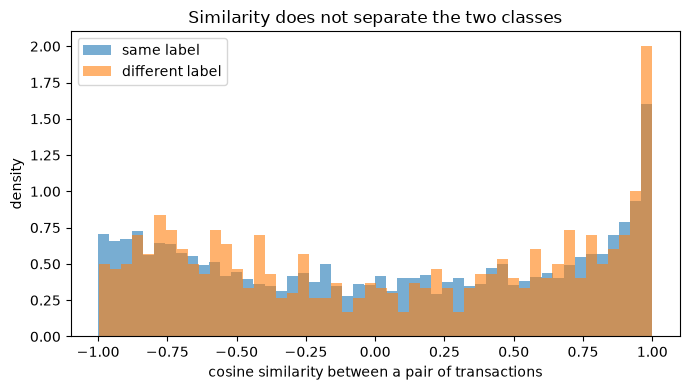

In [10]:
rng = np.random.default_rng(cs.SEED)
pairs = rng.integers(0, n, size=(4000, 2))
pairs = pairs[pairs[:, 0] != pairs[:, 1]]

lab = sample["isFraud"].to_numpy()
norms = np.linalg.norm(Z, axis=1)
ok = (norms[pairs[:, 0]] > 0) & (norms[pairs[:, 1]] > 0)
pairs = pairs[ok]

cosines = np.einsum("ij,ij->i", Z[pairs[:, 0]], Z[pairs[:, 1]]) / (
    norms[pairs[:, 0]] * norms[pairs[:, 1]])
same = lab[pairs[:, 0]] == lab[pairs[:, 1]]

print(f"pairs compared     : {len(pairs):,}")
print(f"same label  : mean cosine {cosines[same].mean():+.4f}  (n={same.sum():,})")
print(f"different   : mean cosine {cosines[~same].mean():+.4f}  (n={(~same).sum():,})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(cosines[same], bins=50, alpha=0.6, density=True, label="same label")
ax.hist(cosines[~same], bins=50, alpha=0.6, density=True, label="different label")
ax.set_xlabel("cosine similarity between a pair of transactions")
ax.set_ylabel("density")
ax.set_title("Similarity does not separate the two classes")
ax.legend()
cs.savefig(fig, "cosine_by_label.png")
plt.show()